# Project 3 — Name Gender Classification with NLTK

### Compared Naive Bayes against a Decision Tree using a training set of 6900, and development test set of 500 with final test set of 500.

**Method:** Naive Bayes, a classifier explicitly covered in Chapter 6

In [1]:
import random
import nltk
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from nltk.corpus import names
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix

nltk.download('names', quiet=True)
SEED = 42
from sklearn.feature_extraction import DictVectorizer
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import accuracy_score


# Load and split data
The NLTK corpus normally has 7944 names. 44 randomly selected users were removed since we want exactly 7900.

In [2]:
labeled_names = ([(name, 'male') for name in names.words('male.txt')] +
                 [(name, 'female') for name in names.words('female.txt')])
print('Total:', len(labeled_names))
print('Full corpus label counts:', Counter(label for _, label in labeled_names))

rng = random.Random(SEED)
rng.shuffle(labeled_names)
selected = labeled_names[:7900]
unused = labeled_names[7900:]


test_names = selected[:500]
devtest_names = selected[500:1000]
train_names = selected[1000:]

assert (len(train_names), len(devtest_names), len(test_names)) == (6900, 500, 500)
print('Train:', len(train_names), '- Dev test:', len(devtest_names),
      '- Test:', len(test_names), '- Unused:', len(unused))
print('Training label counts:', Counter(label for _, label in train_names))
print('Development label counts:', Counter(label for _, label in devtest_names))

Total labeled entries: 7944
Full corpus label counts: Counter({'female': 5001, 'male': 2943})
Train: 6900 | Dev-test: 500 | Test: 500 | Unused: 44
Training label counts: Counter({'female': 4363, 'male': 2537})
Development label counts: Counter({'female': 297, 'male': 203})


# Define feature extractors

In [3]:
def features_baseline(name):
    word = name.lower()
    return {'last_letter': word[-1]}


def features_suffix2(name):
    word = name.lower()
    return {'suffix1': word[-1:], 'suffix2': word[-2:]}


def features_prefix_suffix(name):
    word = name.lower()
    return {'first_letter': word[0],
            'suffix1': word[-1:], 'suffix2': word[-2:], 'suffix3': word[-3:]}


def features_structure(name):
    word = name.lower()
    features = features_prefix_suffix(name)
    features.update({
        'prefix2': word[:2],
        'length_bin': min(len(word), 12),
        'vowel_count_bin': min(sum(c in 'aeiou' for c in word), 6),
        'ends_in_vowel': word[-1] in 'aeiou',
    })
    return features


def features_positions(name):
    word = name.lower()
    features = features_structure(name)
    features.update({
        'second_letter': word[1] if len(word) > 1 else '<NONE>',
        'second_last_letter': word[-2] if len(word) > 1 else '<NONE>',
        'third_last_letter': word[-3] if len(word) > 2 else '<NONE>',
    })
    return features

feature_experiments = {
    '1. Baseline (last letter)': features_baseline,
    '2. Last 1–2 letters': features_suffix2,
    '3. Prefix + suffixes': features_prefix_suffix,
    '4. Name structure': features_structure,
    '5. Position patterns': features_positions,
}

print('Example name:', 'Amanda')
for title, feature_fn in feature_experiments.items():
    print(title, feature_fn('Amanda'))

Example name: Amanda
1. Baseline (last letter) {'last_letter': 'a'}
2. Last 1–2 letters {'suffix1': 'a', 'suffix2': 'da'}
3. Prefix + suffixes {'first_letter': 'a', 'suffix1': 'a', 'suffix2': 'da', 'suffix3': 'nda'}
4. Name structure {'first_letter': 'a', 'suffix1': 'a', 'suffix2': 'da', 'suffix3': 'nda', 'prefix2': 'am', 'length_bin': 6, 'vowel_count_bin': 3, 'ends_in_vowel': True}
5. Position patterns {'first_letter': 'a', 'suffix1': 'a', 'suffix2': 'da', 'suffix3': 'nda', 'prefix2': 'am', 'length_bin': 6, 'vowel_count_bin': 3, 'ends_in_vowel': True, 'second_letter': 'm', 'second_last_letter': 'd', 'third_last_letter': 'n'}


# Run incremental experiments on the DEV TEST set
Every experiment uses the same training and dev test examples.

In [4]:
results = []
trained_models = {}

for experiment, feature_fn in feature_experiments.items():
    train_features = [(feature_fn(name), label) for name, label in train_names]
    dev_features = [(feature_fn(name), label) for name, label in devtest_names]

    model = nltk.NaiveBayesClassifier.train(train_features)
    dev_accuracy = nltk.classify.accuracy(model, dev_features)
    results.append({'Experiment': experiment, 'Dev accuracy': dev_accuracy,
                    'Correct out of 500': round(dev_accuracy * 500)})
    trained_models[experiment] = model

results_df = pd.DataFrame(results)
results_df['Dev accuracy (%)'] = (results_df['Dev accuracy'] * 100).round(2)
print(results_df[['Experiment', 'Correct out of 500', 'Dev accuracy (%)']].to_string(index=False))

               Experiment  Correct out of 500  Dev accuracy (%)
1. Baseline (last letter)                 377              75.4
      2. Last 1–2 letters                 390              78.0
     3. Prefix + suffixes                 397              79.4
        4. Name structure                 405              81.0
     5. Position patterns                 401              80.2


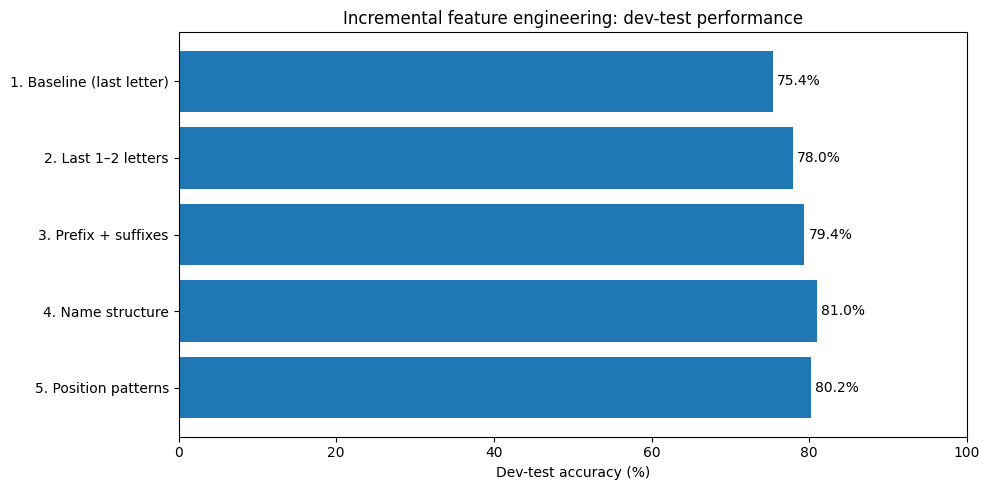

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(results_df['Experiment'], results_df['Dev accuracy (%)'])
ax.invert_yaxis()
ax.set_xlabel('Dev-test accuracy (%)')
ax.set_title('Incremental feature engineering: dev-test performance')
ax.set_xlim(0, 100)
for i, value in enumerate(results_df['Dev accuracy (%)']):
    ax.text(value + 0.5, i, f'{value:.1f}%', va='center')
plt.tight_layout()
plt.show()

# Inspect some errors on the dev test set
Inspecting failures just to understand better about wrong predictions. Against my own judgement I consider the predictions accuracy. This is a situation where human intuition can inexplicably identify gendered names based on recall and rules set by experience that a person may not be able to define.

In [6]:
best_row = results_df.sort_values('Dev accuracy', ascending=False).iloc[0]
best_experiment = best_row['Experiment']
best_feature_fn = feature_experiments[best_experiment]
best_model = trained_models[best_experiment]
best_dev_accuracy = float(best_row['Dev accuracy'])

errors = []
for name, true_label in devtest_names:
    predicted = best_model.classify(best_feature_fn(name))
    if predicted != true_label:
        errors.append({'Name': name, 'Actual': true_label, 'Predicted': predicted})

print('Selected:', best_experiment)
print(f'Dev-test accuracy: {best_dev_accuracy:.2%}')
print('Development errors:', len(errors))
print(pd.DataFrame(errors).head(25).to_string(index=False))

Selected: 4. Name structure
Dev-test accuracy: 81.00%
Development errors: 95
     Name Actual Predicted
   Cherey female      male
    Marlo female      male
Hildagard female      male
 Melicent female      male
     Moll female      male
  Georgie   male    female
   Charil female      male
     Elly female      male
  Etienne   male    female
 Joycelin female      male
    Vinny   male    female
  Yehudit female      male
      Ivy female      male
    Trudy female      male
  Margalo female      male
    Andre   male    female
    Benji   male    female
 Martainn   male    female
     Pris female      male
    Trish female      male
     Dory female      male
   Gillan female      male
  Lindsay female      male
      Ole   male    female
 Ginnifer female      male


# Inspect best model's most useful features

In [7]:
best_model.show_most_informative_features(15)

Most Informative Features
                 suffix2 = 'na'           female : male   =     93.7 : 1.0
                 suffix2 = 'la'           female : male   =     70.7 : 1.0
                 suffix3 = 'ard'            male : female =     43.4 : 1.0
                 suffix2 = 'rd'             male : female =     38.1 : 1.0
                 suffix2 = 'ia'           female : male   =     35.9 : 1.0
                 suffix2 = 'sa'           female : male   =     32.3 : 1.0
                 suffix1 = 'a'            female : male   =     31.7 : 1.0
                 suffix2 = 'ta'           female : male   =     29.3 : 1.0
                 suffix3 = 'nne'          female : male   =     29.1 : 1.0
                 suffix1 = 'k'              male : female =     28.2 : 1.0
                 suffix2 = 'us'             male : female =     27.2 : 1.0
                 suffix1 = 'f'              male : female =     26.9 : 1.0
                 suffix2 = 'io'             male : female =     26.4 : 1.0

# Compare Naive Bayes with a Decision Tree

We keep the same selected feature set, training names, and development names for both. The Decision Tree automatically learns if/then splits and we constrain its depth and leaf size to reduce overfitting.

In [8]:
#Reuse the best feature selected using the Naive Bayes experiments.
train_dicts = [best_feature_fn(name) for name, _ in train_names]
dev_dicts = [best_feature_fn(name) for name, _ in devtest_names]
y_train = [label for _, label in train_names]
y_dev = [label for _, label in devtest_names]

#One hot encoding turns feature dictionaries into tree inputs.
vectorizer = DictVectorizer(sparse=False)
X_train = vectorizer.fit_transform(train_dicts)
X_dev = vectorizer.transform(dev_dicts)

decision_tree = DecisionTreeClassifier(
    max_depth=8, min_samples_leaf=10, random_state=SEED
)
decision_tree.fit(X_train, y_train)
tree_dev_predictions = decision_tree.predict(X_dev)
tree_dev_accuracy = accuracy_score(y_dev, tree_dev_predictions)

model_comparison = pd.DataFrame([
    {'Classifier': 'Naive Bayes', 'Dev-test accuracy': best_dev_accuracy},
    {'Classifier': 'Decision Tree', 'Dev-test accuracy': tree_dev_accuracy},
])
model_comparison['Accuracy (%)'] = (100 * model_comparison['Dev-test accuracy']).round(2)
print(model_comparison[['Classifier', 'Accuracy (%)']].to_string(index=False))
print(f'\nDecision Tree depth: {decision_tree.get_depth()}')
print(f'Decision Tree leaves: {decision_tree.get_n_leaves()}')

   Classifier  Accuracy (%)
  Naive Bayes          81.0
Decision Tree          79.2

Decision Tree depth: 8
Decision Tree leaves: 63


#Visualizing Tree Rules

In [9]:
print(export_text(
    decision_tree,
    feature_names=list(vectorizer.get_feature_names_out()),
    max_depth=3,
))

|--- ends_in_vowel <= 0.50
|   |--- suffix1=y <= 0.50
|   |   |--- suffix2=yn <= 0.50
|   |   |   |--- suffix3=een <= 0.50
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- suffix3=een >  0.50
|   |   |   |   |--- class: female
|   |   |--- suffix2=yn >  0.50
|   |   |   |--- length_bin <= 4.50
|   |   |   |   |--- class: female
|   |   |   |--- length_bin >  4.50
|   |   |   |   |--- truncated branch of depth 4
|   |--- suffix1=y >  0.50
|   |   |--- suffix2=sy <= 0.50
|   |   |   |--- prefix2=ka <= 0.50
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- prefix2=ka >  0.50
|   |   |   |   |--- class: female
|   |   |--- suffix2=sy >  0.50
|   |   |   |--- suffix3=ssy <= 0.50
|   |   |   |   |--- class: female
|   |   |   |--- suffix3=ssy >  0.50
|   |   |   |   |--- class: female
|--- ends_in_vowel >  0.50
|   |--- suffix1=o <= 0.50
|   |   |--- suffix1=a <= 0.50
|   |   |   |--- suffix2=ke <= 0.50
|   |   |   |   |--- truncated branch of depth 5
|   |  

# Choose the final classifier by accuracy

We select whichever of the two performed better on the dev test. In this case it is the Naive Bayes.

In [10]:
winner = 'Decision Tree' if tree_dev_accuracy > best_dev_accuracy else 'Naive Bayes'
selected_dev_accuracy = max(best_dev_accuracy, tree_dev_accuracy)
print('Chosen model:', winner)
print('Chosen features:', best_experiment)
print(f'Dev-test accuracy: {selected_dev_accuracy:.2%}')

def predict_selected(names_list):
    name_features = [best_feature_fn(name) for name in names_list]
    if winner == 'Decision Tree':
        return list(decision_tree.predict(vectorizer.transform(name_features)))
    return [best_model.classify(features) for features in name_features]


Chosen model: Naive Bayes
Chosen features: 4. Name structure
Dev-test accuracy: 81.00%


In [14]:
# FINAL
y_test = [label for _, label in test_names]
final_predictions = predict_selected([name for name, _ in test_names])
final_test_accuracy = accuracy_score(y_test, final_predictions)
gap = final_test_accuracy - selected_dev_accuracy

print('Chosen classifier:', winner)
print('Chosen feature set:', best_experiment)
print(f'Dev test accuracy: {selected_dev_accuracy:.2%} ({round(selected_dev_accuracy * 500)}/500)')
print(f'Final test accuracy: {final_test_accuracy:.2%} ({round(final_test_accuracy * 500)}/500)')

if abs(gap) < 0.02:
    print('Interpretation: The results are fairly similar; minor differences are expected.')
elif gap < 0:
    print('Interpretation: The test result is lower; development-set selection may contribute to optimism.')
else:
    print('Interpretation: The test result is higher; random sampling variation can produce this too.')

Chosen classifier: Naive Bayes
Chosen feature set: 4. Name structure
Dev test accuracy: 81.00% (405/500)
Final test accuracy: 78.00% (390/500)
Interpretation: The test result is lower; development-set selection may contribute to optimism.


# Final confusion matrix and classification report


              precision    recall  f1-score   support

      female       0.85      0.79      0.82       316
        male       0.68      0.76      0.72       184

    accuracy                           0.78       500
   macro avg       0.76      0.78      0.77       500
weighted avg       0.79      0.78      0.78       500



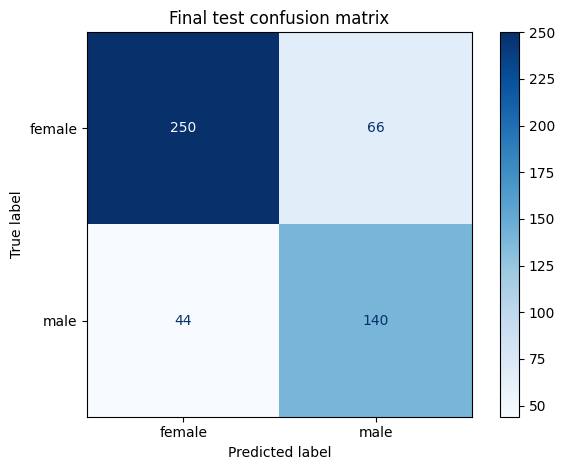

In [12]:
y_true = [label for _, label in test_names]
y_pred = final_predictions
print(classification_report(y_true, y_pred, labels=['female', 'male'], zero_division=0))
cm = confusion_matrix(y_true, y_pred, labels=['female', 'male'])
ConfusionMatrixDisplay(cm, display_labels=['female', 'male']).plot(cmap='Blues')
plt.title('Final test confusion matrix')
plt.tight_layout()
plt.show()

# Results

Our final Naive Bayes classifier achieved an overall test accuracy of 78%, correctly classifying 390 of the 500 names in the test set. The model interestingly performed better when predicting the female names getting 85% precision compared with 68% precision for male names. Recall was relatively similar between the two categories at 79% for female and 76% for male. This suggests the classifier was definitely effective at identifying the names but the male predictions were more likely to be incorrect. One possible explanation is simply the skew in the dataset which contains more female names than male names. The macro F1 score of 77% is good but broken down it shows the difference as the female F1 score 0.82, and the male F1 score of 0.72 definitely indicates that the classifier performs better on female names.